In [2]:
from matplotlib import pyplot as plt
from pathlib import Path
import sys
import pandas as pd
import cv2
from tqdm import tqdm
import seaborn as sns
import random
import numpy as np
import tensorflow as tf

PROJECT_ROOT = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "src" / "preprocessing" / "video_preprocessing.py").is_file()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not find the project root containing src/preprocessing/video_preprocessing.py")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Read Data


In [5]:
DATASET_PATH = PROJECT_ROOT / "data" / "raw" / "RWF-2000"

splits = ["train", "val"]
classes = ["Fight", "NonFight"]

records = []

for split in splits:
    for class_name in classes:

        folder = DATASET_PATH / split / class_name

        if not folder.exists():
            print(f"Missing folder: {folder}")
            continue

        videos = [
            file for file in folder.iterdir()
            if file.is_file()
        ]

        records.append({
            "Split": split,
            "Class": class_name,
            "Video_Count": len(videos)
        })

df = pd.DataFrame(records)

print(df)

print("\nTotal videos:", df["Video_Count"].sum())

print("\nTotal per split:")
print(df.groupby("Split")["Video_Count"].sum())

print("\nTotal per class:")
print(df.groupby("Class")["Video_Count"].sum())


   Split     Class  Video_Count
0  train     Fight          800
1  train  NonFight          800
2    val     Fight          200
3    val  NonFight          200

Total videos: 2000

Total per split:
Split
train    1600
val       400
Name: Video_Count, dtype: int64

Total per class:
Class
Fight       1000
NonFight    1000
Name: Video_Count, dtype: int64


# data extraction from video


In [6]:
video_extensions = {
    ".mp4", ".avi", ".mov", ".mkv"
}
records = []

for split in splits:
    for class_name in classes:
        folder = DATASET_PATH / split / class_name
        videos = [
            file for file in folder.iterdir()
            if file.is_file()
            and file.suffix.lower() in video_extensions
        ]
        
        for video_path in tqdm(videos,desc=f"{split} / {class_name}"):
            cap = cv2.VideoCapture(str(video_path))
            fps=cap.get(cv2.CAP_PROP_FPS)
            frame_count= int (cap.get(cv2.CAP_PROP_FRAME_COUNT))
            width=int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
            height=int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
            is_opened=cap.isOpened()
            duration =(frame_count/fps
                       if fps > 0 else 0 )
            file_size=(video_path.stat().st_size/(1024**2))
            
            is_valid = (
                is_opened
                and fps > 0
                and frame_count > 0
                and width > 0
                and height > 0
            )
            
            records.append({
                "Filename": video_path.name,
                "Split": split,
                "Class": class_name,
                "FPS": fps,
                "Frame_Count": frame_count,
                "Duration": duration,
                "Width": width,
                "Height": height,
                "File_Size_MB": file_size,
                "Is_Valid": is_valid
            })
            cap.release()



metadata_df = pd.DataFrame(records)
metadata_df.to_csv(
    "../data/meta_data/video_metadata.csv",
    index=False
)

print("Total videos:", len(metadata_df))
print("\nValid videos:")
print(metadata_df["Is_Valid"].value_counts())

print("\nMetadata summary:")
print(metadata_df.describe())


val / NonFight: 100%|██████████| 200/200 [00:00<00:00, 1724.12it/s]


Total videos: 2000

Valid videos:
Is_Valid
True    2000
Name: count, dtype: int64

Metadata summary:
          FPS  Frame_Count  Duration        Width       Height  File_Size_MB
count  2000.0       2000.0    2000.0  2000.000000  2000.000000   2000.000000
mean     30.0        150.0       5.0   724.245000   445.330000      6.056811
std       0.0          0.0       0.0   439.697383   225.650886      5.244503
min      30.0        150.0       5.0   204.000000   188.000000      0.642509
25%      30.0        150.0       5.0   320.000000   240.000000      2.480366
50%      30.0        150.0       5.0   527.000000   360.000000      3.579685
75%      30.0        150.0       5.0  1280.000000   720.000000      8.473924
max      30.0        150.0       5.0  1920.000000  1080.000000     36.236343


# EDA


video validity ....
Is_Valid
True    2000
Name: count, dtype: int64

 top 10 resolution : 
resolution
320x240      700
1280x720     628
640x360      169
480x360       89
1920x1080     31
398x224       22
352x288       16
406x720       14
426x240       14
424x320       13
Name: count, dtype: int64

Class-wise analysis:
           FPS  Duration   Width  Height  File_Size_MB
Class                                                 
Fight     30.0       5.0  841.10  504.24          6.89
NonFight  30.0       5.0  607.39  386.42          5.23


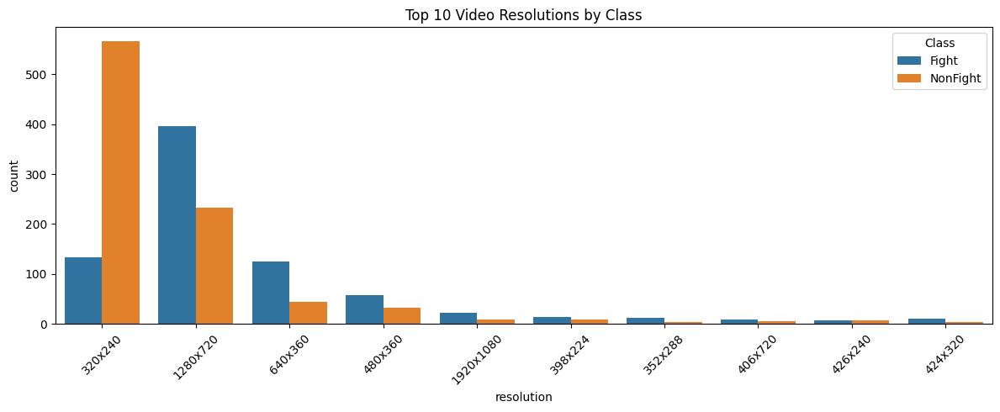

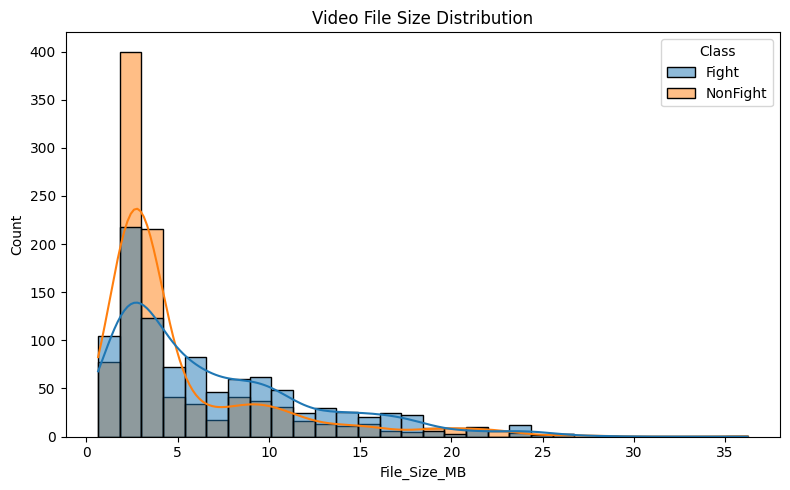

In [7]:
print("video validity ....")
print(metadata_df["Is_Valid"].value_counts())

metadata_df["resolution"]=(
    metadata_df["Width"].astype(str)
    +"x"
    +metadata_df["Height"].astype(str)
)

print("\n top 10 resolution : ")
print(metadata_df["resolution"].value_counts().head(10))

print("\nClass-wise analysis:")
print(
    metadata_df.groupby("Class")[
        ["FPS", "Duration", "Width", "Height", "File_Size_MB"]
    ].mean().round(2)
)

plt.figure(figsize=(12, 5))

sns.countplot(
    data=metadata_df,
    x="resolution",
    hue="Class",
    order=metadata_df["resolution"].value_counts().head(10).index
)

plt.title("Top 10 Video Resolutions by Class")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 5))

sns.histplot(
    data=metadata_df,
    x="File_Size_MB",
    hue="Class",
    bins=30,
    kde=True
)
plt.title("Video File Size Distribution")
plt.tight_layout()
plt.show()


# Select Sample video


In [8]:
random.seed(42)
samples = {}

for split in splits:
    for class_name in classes:
        video_folder = DATASET_PATH / split / class_name
        videos= list(video_folder.glob("*.avi"))
        selected_videos=random.sample(videos,2)
        samples["class_name"]=selected_videos
        print(f"\n{class_name} samples:")
        for video in selected_videos:
            print(video.name)


Fight samples:
trhfd_1019.avi
6mrIIcAQ2fI_0.avi

NonFight samples:
1A3zEkCHBl8_0.avi
xxIkl4Ue_0.avi

Fight samples:
I-QiUMPTWNE_1.avi
g-qjkePEXQA_3.avi

NonFight samples:
Fds7C6sp_0.avi
Assault006_x264_1.avi


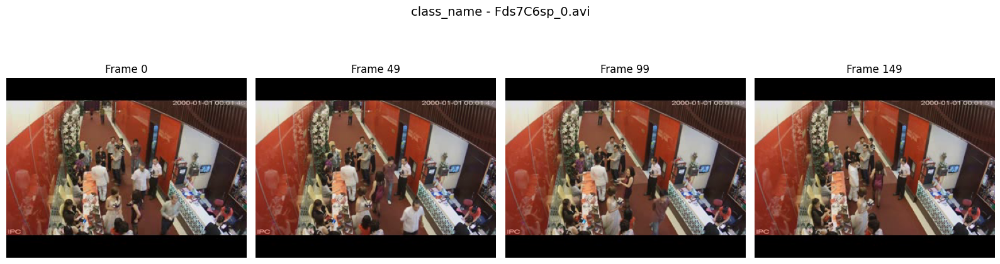

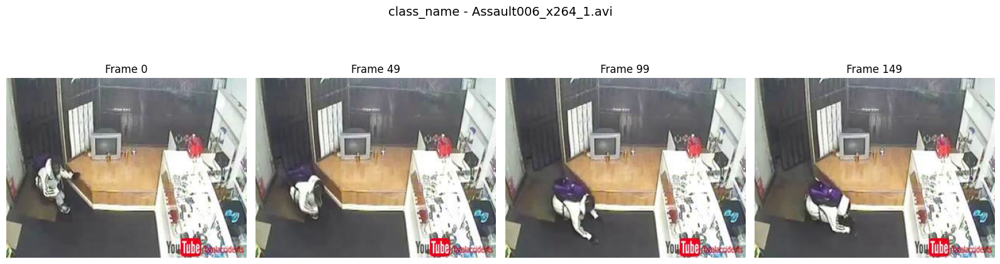

In [9]:
for class_name,videos in samples.items():
    for video_path in videos:
        cap=cv2.VideoCapture(str(video_path))
        total_frames=int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        frame_indices = np.linspace(
            0, total_frames - 1, 4, dtype=int
        )
        frames = []

        for frame_idx in frame_indices:

            cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))

            success, frame = cap.read()

            if success:
                frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                frames.append(frame)

        cap.release()

        fig, axes = plt.subplots(1, len(frames), figsize=(16, 5))

        fig.suptitle(
            f"{class_name} - {video_path.name}",
            fontsize=14
        )

        for ax, frame, idx in zip(axes, frames, frame_indices):
            ax.imshow(frame)
            ax.set_title(f"Frame {idx}")
            ax.axis("off")

        plt.tight_layout()
        plt.show()

# apply video preprocessor


Tensor Shape: (16, 224, 224, 3)
Data Type: float32
Minimum: 0.0
Maximum: 1.0


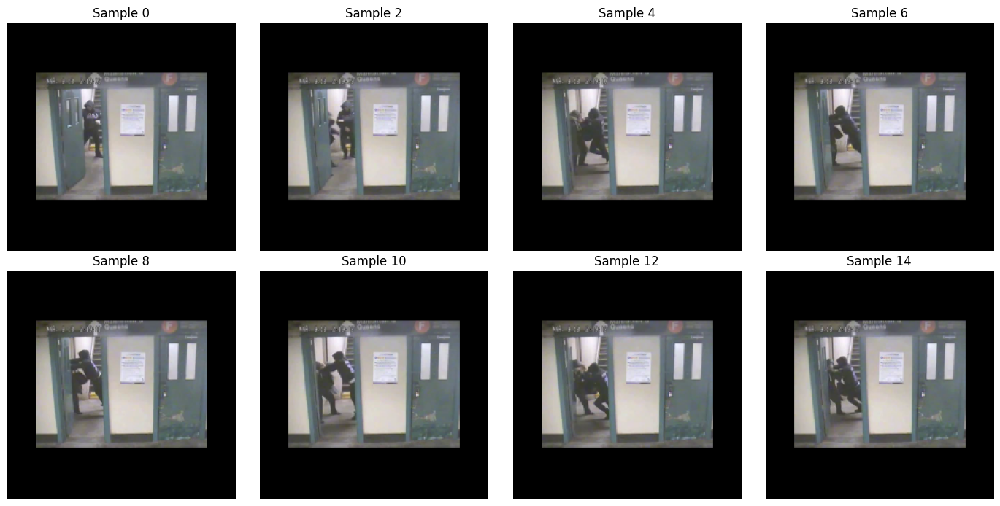

In [10]:
import sys

PROJECT_ROOT = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "src" / "preprocessing" / "video_preprocessing.py").is_file()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not find the project root containing src/preprocessing/video_preprocessing.py")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing.video_preprocessing import VideoPreprocessor

processor = VideoPreprocessor(
    num_frames=16,
    image_size=224
)

video_path = PROJECT_ROOT / "data" / "raw" / "RWF-2000" / "train" / "Fight"

sample_video = next(video_path.glob("*.avi"))

video_tensor = processor.process_video(sample_video)

print("Tensor Shape:", video_tensor.shape)
print("Data Type:", video_tensor.dtype)
print("Minimum:", video_tensor.min())
print("Maximum:", video_tensor.max())

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i, ax in enumerate(axes.flat):
    ax.imshow(video_tensor[i * 2])
    ax.set_title(f"Sample {i * 2}")
    ax.axis("off")

plt.tight_layout()
plt.show()


# Test Preprocessing


In [11]:
from src.preprocessing.video_loader import load_video
video_path = "D:\\projects\\Depi_CV\\fight_detection_system\\data\\raw\\RWF-2000\\train\\Fight\\_2RYnSFPD_U_0.avi"
frames = load_video(video_path)

print("Frames shape:", frames.shape)
print("Data type:", frames.dtype)
print("Min value:", frames.min())
print("Max value:", frames.max())


Frames shape: (16, 224, 224, 3)
Data type: float32
Min value: 0.0
Max value: 0.98039216


Resize إلى 224 × 224.

Preserve Aspect Ratio باستخدام Padding.

Normalization من 0–255 إلى 0–1.

\*\* because video have different dimention


# after apply preprocess frame


In [12]:
video_path = "D:\\projects\\Depi_CV\\fight_detection_system\\data\\raw\\RWF-2000\\train\\Fight\\_2RYnSFPD_U_0.avi"
frames = load_video(video_path)

print("Shape:", frames.shape)
print("Data Type:", frames.dtype)
print("Min Value:", frames.min())
print("Max Value:", frames.max())


Shape: (16, 224, 224, 3)
Data Type: float32
Min Value: 0.0
Max Value: 0.98039216


# Test data set


In [13]:
from src.preprocessing.dataset import create_dataset

DATASET_PATH = Path(
    r"D:\projects\Depi_CV\fight_detection_system\data\raw\RWF-2000"
)

train_path = DATASET_PATH / "train"
val_path = DATASET_PATH / "val"

print("Train exists:", train_path.exists())
print("Validation exists:", val_path.exists())

train_dataset = create_dataset(
    str(train_path),
    training=True
)

val_dataset = create_dataset(
    str(val_path),
    training=False
)

for videos, labels in train_dataset.take(1):

    print("Videos Shape:", videos.shape)
    print("Labels Shape:", labels.shape)

    print("Videos dtype:", videos.dtype)
    print("Labels:", labels.numpy())

    print("Min Pixel:", tf.reduce_min(videos).numpy())
    print("Max Pixel:", tf.reduce_max(videos).numpy())


Train exists: True
Validation exists: True
Videos Shape: (4, 16, 224, 224, 3)
Labels Shape: (4,)
Videos dtype: <dtype: 'float32'>
Labels: [0 1 1 1]
Min Pixel: 0.0
Max Pixel: 1.0


# Visualize sampled frames


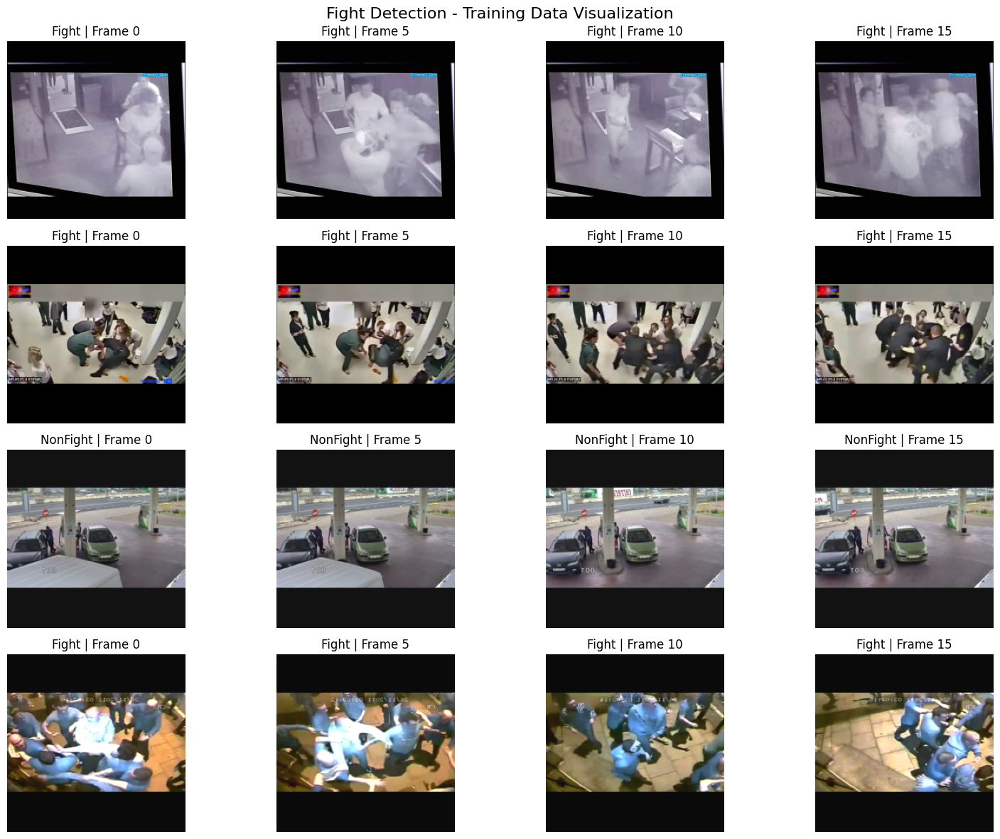

In [14]:
# Get one batch
videos, labels = next(iter(train_dataset))

# Select 4 videos and 4 frames per video
selected_frames = [0, 5, 10, 15]

fig, axes = plt.subplots(
    len(videos),
    len(selected_frames),
    figsize=(16, 12)
)

class_names = {
    0: "NonFight",
    1: "Fight"
}

for i in range(len(videos)):

    for j, frame_idx in enumerate(selected_frames):

        frame = videos[i, frame_idx].numpy()

        axes[i, j].imshow(frame)

        axes[i, j].set_title(
            f"{class_names[int(labels[i])]} | Frame {frame_idx}"
        )

        axes[i, j].axis("off")

plt.suptitle(
    "Fight Detection - Training Data Visualization",
    fontsize=16
)

plt.tight_layout()
plt.show()


# test augmentation


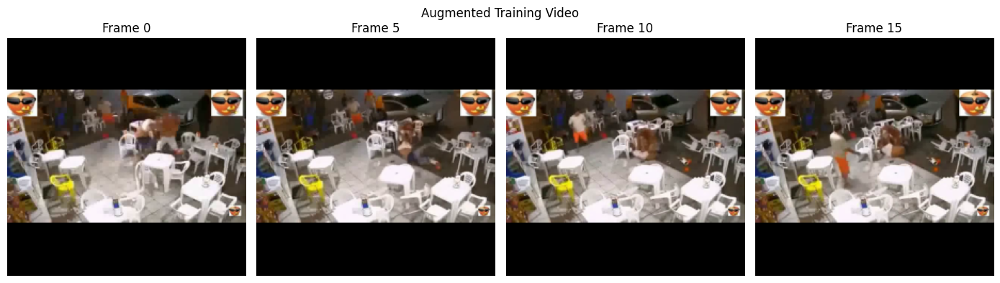

In [15]:
videos, labels = next(iter(train_dataset))

video = videos[0]

fig, axes = plt.subplots(1, 4, figsize=(14, 4))

for i, frame_idx in enumerate([0, 5, 10, 15]):

    axes[i].imshow(video[frame_idx].numpy())

    axes[i].set_title(f"Frame {frame_idx}")

    axes[i].axis("off")

plt.suptitle("Augmented Training Video")
plt.tight_layout()
plt.show()


In [16]:
from importlib import reload
import src.preprocessing.dataset as dataset_module

reload(dataset_module)

train_dataset = dataset_module.create_dataset(
    str(train_path),
    training=True
)

val_dataset = dataset_module.create_dataset(
    str(val_path),
    training=False
)

In [17]:
videos, labels = next(iter(train_dataset))

print("Train Videos Shape:", videos.shape)
print("Train Labels Shape:", labels.shape)
print("Train Min Pixel:", videos.numpy().min())
print("Train Max Pixel:", videos.numpy().max())

val_videos, val_labels = next(iter(val_dataset))

print("\nValidation Videos Shape:", val_videos.shape)
print("Validation Labels Shape:", val_labels.shape)
print("Validation Min Pixel:", val_videos.numpy().min())
print("Validation Max Pixel:", val_videos.numpy().max())

Train Videos Shape: (4, 16, 224, 224, 3)
Train Labels Shape: (4,)
Train Min Pixel: 0.0
Train Max Pixel: 1.0

Validation Videos Shape: (4, 16, 224, 224, 3)
Validation Labels Shape: (4,)
Validation Min Pixel: 0.0
Validation Max Pixel: 1.0


In [18]:
from src.models.cnn_lstm import build_cnn_lstm

model = build_cnn_lstm()

model.summary()

print("Input Shape:", model.input_shape)
print("Output Shape:", model.output_shape)
print("Total Parameters:", model.count_params())
print("Trainable Parameters:", sum(
    tf.size(v).numpy() for v in model.trainable_variables
))


Model: "Fight_Detection_CNN_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 16, 224, 224,   │             0 │
│                                 │ 3)                     │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 16, 7, 7, 2048) │    23,587,712 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 16, 2048)       │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │     1,114,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,702,465 (94.23 MB)

 Trainable params: 1,114,753 (4.25 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

Input Shape: (None, 16, 224, 224, 3)
Output Shape: (None, 1)
Total Parameters: 24702465
Trainable Parameters: 1114753


In [19]:
from src.models.cnn_lstm import build_cnn_lstm_fine_tune

model = build_cnn_lstm_fine_tune(fine_tune=True)

model.summary()

print("Input Shape:", model.input_shape)
print("Output Shape:", model.output_shape)
print("Total Parameters:", model.count_params())
print("Trainable Parameters:", sum(
    tf.size(v).numpy() for v in model.trainable_variables
))


Model: "Fight_Detection_CNN_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 16, 224, 224,   │             0 │
│                                 │ 3)                     │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ frame_feature_extractor         │ (None, 16, 7, 7, 1280) │     2,257,984 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_2              │ (None, 16, 1280)       │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 128)            │       721,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,979,521 (11.37 MB)

 Trainable params: 1,916,417 (7.31 MB)

 Non-trainable params: 1,063,104 (4.06 MB)

Input Shape: (None, 16, 224, 224, 3)
Output Shape: (None, 1)
Total Parameters: 2979521
Trainable Parameters: 1916417


In [20]:

from src.models.cnn_lstm import build_cnn_lstm_fine_tune
from src.training.compile import compile_model

model = build_cnn_lstm_fine_tune(fine_tune=False)

model = compile_model(
    model,
    learning_rate=1e-5
)

print("Model compiled successfully!")
print("Optimizer:", model.optimizer.__class__.__name__)
print("Loss:", model.loss)
print("Metrics:", [m.name for m in model.metrics])


Model compiled successfully!
Optimizer: Adam
Loss: binary_crossentropy
Metrics: ['loss', 'compile_metrics']


In [21]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

print("GPU Available:", tf.config.list_physical_devices('GPU'))

print("CPU:", tf.config.list_physical_devices('CPU'))

if tf.config.list_physical_devices('GPU'):
    print("\n GPU IS AVAILABLE")
else:
    print("\n RUNNING ON CPU")

TensorFlow version: 2.20.0
GPU Available: []
CPU: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]

 RUNNING ON CPU


In [23]:
%run ../src/training/train.py

Datasets loaded successfully!

========== PHASE 1 ==========
Epoch 1/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 0s 404ms/step - accuracy: 0.5526 - auc: 0.5605 - loss: 0.7170 - precision: 0.5500 - recall: 0.7156
Epoch 1: val_loss improved from None to 0.65347, saving model to D:\projects\Depi_CV\fight_detection_system\models\checkpoints\best_phase1.keras

Epoch 1: finished saving model to D:\projects\Depi_CV\fight_detection_system\models\checkpoints\best_phase1.keras
400/400 ━━━━━━━━━━━━━━━━━━━━ 253s 557ms/step - accuracy: 0.5650 - auc: 0.5996 - loss: 0.6935 - precision: 0.5565 - recall: 0.6400 - val_accuracy: 0.6125 - val_auc: 0.6659 - val_loss: 0.6535 - val_precision: 0.6380 - val_recall: 0.5200 - learning_rate: 1.0000e-05
Epoch 2/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 0s 486ms/step - accuracy: 0.5915 - auc: 0.6329 - loss: 0.6717 - precision: 0.5703 - recall: 0.5239
Epoch 2: val_loss improved from 0.65347 to 0.62937, saving model to D:\projects\Depi_CV\fight_detection_system\models\checkpoints\best_pha

In [24]:
%run ../src/training/visualize.py

In [28]:
%run ../src/training/evaluate.py


Loading model...
Model loaded successfully!


Model: "Fight_Detection_CNN_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 16, 224, 224,   │             0 │
│                                 │ 3)                     │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ frame_feature_extractor         │ (None, 16, 7, 7, 1280) │     2,257,984 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_4              │ (None, 16, 1280)       │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 128)            │       721,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,812,357 (25.99 MB)

 Trainable params: 1,916,417 (7.31 MB)

 Non-trainable params: 1,063,104 (4.06 MB)

 Optimizer params: 3,832,836 (14.62 MB)


Loading validation dataset...
Validation videos: 400
True labels collected: 400

Generating predictions...
100/100 ━━━━━━━━━━━━━━━━━━━━ 146s 1s/step

========== EVALUATION RESULTS ==========
Accuracy : 0.7100
Precision: 0.7100
Recall   : 0.7100
F1 Score : 0.7100

Classification Report:

              precision    recall  f1-score   support

    NonFight       0.71      0.71      0.71       200
       Fight       0.71      0.71      0.71       200

    accuracy                           0.71       400
   macro avg       0.71      0.71      0.71       400
weighted avg       0.71      0.71      0.71       400


True Negatives : 142
False Positives: 58
False Negatives: 58
True Positives : 142
ROC AUC: 0.8147

========== ERROR ANALYSIS ==========
Total videos: 400
Correct predictions: 284
Misclassified videos: 116
False Positives: 58
False Negatives: 58

First 10 Misclassified Videos:

            Video Actual_Class  Probability Predicted_Class     Error_Type
   1AURh0Wj_0.avi     NonFight

In [30]:
%run ../src/training/error_analysis.py


Best Threshold Results
threshold: 0.2000
precision: 0.6587
recall: 0.9650
f1: 0.7830
accuracy: 0.7325

Error Analysis
True Negatives: 100
False Positives: 100
False Negatives: 7
True Positives: 193

Incorrect Predictions: 107
Wrong Prediction Indices: [  1   2   3   4   5   6   7   8   9  10  11  12  13  14  16  17  20  21
  22  24  26  27  32  33  35  42  43  46  51  52  53  54  55  57  59  60
  69  70  71  74  76  78  79  80  82  83  84  85  93  94  98  99 102 103
 104 105 106 107 108 109 110 112 116 118 120 121 124 127 129 131 132 133
 138 141 143 147 149 151 153 157 158 160 161 164 171 174 175 176 177 178
 179 180 183 185 189 190 192 193 194 196 207 208 242 244 277 286 289]

Error analysis completed!


# test video


In [3]:
import os
import cv2
import numpy as np
import tensorflow as tf

from pathlib import Path
from IPython.display import display, Video

# Project root
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

os.chdir(PROJECT_ROOT)

# Load trained model
MODEL_PATH = r"C:\Users\Mahmoud\Downloads\fight_detection_project-main\fight_detection_project-main\models\checkpoints\best_phase2.keras"

model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

print("Model loaded successfully!")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

Model loaded successfully!
Input shape: (None, 16, 224, 224, 3)
Output shape: (None, 1)


In [4]:
def preprocess_frame(frame, target_size=(224, 224)):

    target_h, target_w = target_size

    h, w = frame.shape[:2]

    scale = min(target_w / w, target_h / h)

    new_w = int(w * scale)
    new_h = int(h * scale)

    resized = cv2.resize(
        frame,
        (new_w, new_h),
        interpolation=cv2.INTER_AREA
    )

    canvas = np.zeros(
        (target_h, target_w, 3),
        dtype=np.uint8
    )

    x_offset = (target_w - new_w) // 2
    y_offset = (target_h - new_h) // 2

    canvas[
        y_offset:y_offset + new_h,
        x_offset:x_offset + new_w
    ] = resized

    # BGR -> RGB
    canvas = cv2.cvtColor(
        canvas,
        cv2.COLOR_BGR2RGB
    )

    return canvas.astype("float32") / 255.0

In [5]:
def load_video(video_path, num_frames=16):

    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        raise ValueError("Cannot open video!")

    total_frames = int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    )

    if total_frames <= 0:
        cap.release()
        raise ValueError("Video contains no readable frames!")

    frame_indices = np.linspace(
        0,
        total_frames - 1,
        num_frames
    ).astype(int)

    frames = []

    for idx in frame_indices:

        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))

        ret, frame = cap.read()

        if not ret:
            cap.release()
            raise ValueError(f"Could not read frame {idx}")

        frame = preprocess_frame(frame)

        frames.append(frame)

    cap.release()

    video_array = np.array(
        frames,
        dtype=np.float32
    )

    # Add batch dimension
    video_array = np.expand_dims(
        video_array,
        axis=0
    )

    return video_array

In [6]:
def predict_video(video_path, threshold=0.5):

    video = load_video(video_path)

    print("Video shape:", video.shape)

    prediction = model.predict(
        video,
        verbose=0
    )

    probability = float(
        np.asarray(prediction).reshape(-1)[0]
    )

    predicted_class = (
        "Fight" if probability >= threshold
        else "NonFight"
    )

    print("\n========== RESULT ==========")

    print("Prediction:", predicted_class)

    print(f"Fight Probability: {probability * 100:.2f}%")

    print(f"NonFight Probability: {(1-probability) * 100:.2f}%")

    print("Threshold:", threshold)

    return predicted_class, probability

In [10]:
video_path = r"C:\Users\Mahmoud\Downloads\جارٍ تسجيل الشاشة 2026-03-28 035632.mp4"

display(Video(video_path, embed=True, width=600))

result, confidence = predict_video(
    video_path,
    threshold=0.5
)

Video shape: (1, 16, 224, 224, 3)

========== RESULT ==========
Prediction: Fight
Fight Probability: 91.93%
NonFight Probability: 8.07%
Threshold: 0.5
